# Прогнозирование стоимости квартир Москвы на несколько лет

**Сравнительное исследование регрессионных моделей по сделкам 2023–2026 гг.**

Модели: статическая и динамическая гедонические Ridge-регрессии, HistGradientBoostingRegressor и CatBoostRegressor. Схема обучения: хронологическая валидация 2025 года, двухэтапный подбор гиперпараметров, проверка на сделках 2026 года.

**Метрики:** MAE, RMSE (млн ₽), R², MAPE (%) и точность `100 − MAPE` (%).


**Установка зависимостей**

```bash
python -m pip install -U numpy pandas scipy scikit-learn catboost matplotlib seaborn joblib notebook ipykernel

jupyter notebook
```

### Датасет содержит следующие колонки:

- `region` — административный округ Москвы.
- `district` — район расположения объекта.
- `street` — улица.
- `wall_material_code` — код материала стен; используется как категориальный признак, а не количественное число.
- `year_build` — год постройки дома.
- `floor` — этаж квартиры.
- `area` — общая площадь квартиры в квадратных метрах.
- `period_start_date` — дата начала периода наблюдения/сделки; из неё извлекается год `period_year`.
- `price` — цена объекта в рублях. Это целевой признак для задачи регрессии.

В качестве признаков используются числовые (`area`, `period_year`, `year_build`, `floor`) и категориальные (`region`, `district`, `street`, `wall_material_code`) признаки. Категориальные признаки кодируются: `region`, `district`, `wall_material_code` — one-hot, `street` — частотным кодированием.

## 1. Подготовка и исследование данных

## Импорт библиотек и параметры проекта


In [1]:
from pathlib import Path
import warnings, time, math
warnings.filterwarnings("default")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

DATA_PATH = Path("СДЕЛКИ_Мос_2023-2026.csv")  
RANDOM_STATE = 42
import joblib
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Ridge
from catboost import CatBoostRegressor
from sklearn.base import clone
from IPython.display import display

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.preprocessing import OrdinalEncoder
from sklearn.utils.validation import check_is_fitted
from scipy.stats import randint, uniform, loguniform
from itertools import product

## Загрузка и проверка структуры данных

Считываем CSV и проверяем обязательные колонки

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"CSV не найден: {DATA_PATH.resolve()}\n"
        "Положите файл рядом с ноутбуком или укажите полный путь в DATA_PATH."
    )

read_error = None
for sep in [None, ";", ",", "\\t"]:
    for encoding in ["utf-8-sig", "cp1251"]:
        try:
            if sep is None:
                loaded = pd.read_csv(DATA_PATH, sep=None, engine="python", encoding=encoding)
            else:
                loaded = pd.read_csv(DATA_PATH, sep=sep, encoding=encoding)
            if loaded.shape[1] >= 5:
                df_raw = loaded.copy()
                break
        except Exception as exc:
            read_error = exc
    else:
        continue
    break
else:
    raise RuntimeError(f"Не удалось прочитать CSV. Последняя ошибка: {read_error}")

df_raw.columns = df_raw.columns.astype(str).str.strip().str.lower()
expected_cols = ["region", "district", "street", "wall_material_code",
                 "year_build", "floor", "area", "period_start_date", "price"]
missing = [c for c in expected_cols if c not in df_raw.columns]
if missing:
    raise ValueError(f"Не найдены колонки {missing}. В файле есть: {df_raw.columns.tolist()}")

print(f"Файл: {DATA_PATH.resolve()}")
print(f"Размер до очистки: {df_raw.shape[0]:,} строк × {df_raw.shape[1]} колонок")
display(df_raw.head())
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "missing": df_raw.isna().sum()}))

Файл: C:\Users\AnnaA\Desktop\модель\СДЕЛКИ_Мос_2023-2026.csv
Размер до очистки: 66,551 строк × 9 колонок


,region,district,street,wall_material_code,year_build,floor,area,period_start_date,price
0,НАО,поселение Внуковское,Анны Ахматовой,61001007000,2016.0,4,39,01.01.2024,14200000
1,НАО,поселение Филимонковское,Жемчужная,61001003000,2021.0,4,40,01.01.2024,44950000
2,СВАО,Алексеевский,Староалексеевская,61001007000,2022.0,21,53,01.01.2024,20000000
3,САО,Хорошевский,Авиаконструктора Сухого,61001006001,2016.0,23,96,01.01.2024,84247949
4,СЗАО,Хорошево-Мневники,Мнёвники,61001006000,2020.0,18,41,01.01.2024,38000000


,dtype,missing
region,str,0
district,str,0
street,str,0
wall_material_code,int64,0
year_build,float64,15
floor,int64,0
area,int64,0
period_start_date,str,0
price,int64,0


## Очистка данных

In [3]:
df = df_raw.drop_duplicates().copy()
print("Удалено полных дубликатов:", len(df_raw) - len(df))

text_cols = ["region", "district", "street", "wall_material_code"]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

def clean_numeric(series):
    s = (series.astype("string")
         .str.replace("\u00a0", "", regex=False)
         .str.replace(" ", "", regex=False)
         .str.replace(",", ".", regex=False))
    return pd.to_numeric(s, errors="coerce")

for col in ["year_build", "floor", "area", "price"]:
    df[col] = clean_numeric(df[col])
try:
    df["period_start_date"] = pd.to_datetime(df["period_start_date"], errors="coerce", format="mixed", dayfirst=True)
except TypeError:
    df["period_start_date"] = pd.to_datetime(df["period_start_date"], errors="coerce", dayfirst=True)
df["period_year"] = df["period_start_date"].dt.year

df = df[(df['area'] > 25) & (df['price'] > 7_000_000)].copy().reset_index(drop=True)

before = len(df)
df = df.dropna(subset=["period_start_date", "price", "area", "year_build", "floor"]).copy()
print("Удалено строк без обязательных даты/цены/площади/этажа/года постройки:", before-len(df))

current_year = pd.Timestamp.today().year
valid = (
    (df["price"] > 0) & (df["area"] > 0) & (df["floor"] >= 1) &
    (df["year_build"].between(1800, current_year + 5)) &
    (df["period_year"].between(1900, current_year + 1)) &
    (df["year_build"] <= df["period_year"] + 1)
)
before = len(df)
df = df.loc[valid].copy()
print("Удалено физически некорректных значений:", before-len(df))

df["year_build"] = df["year_build"].round().astype(int)
df["floor"] = df["floor"].round().astype(int)
df["period_year"] = df["period_year"].astype(int)
df["price"] = df["price"].astype(float)
df["price_per_sqm"] = df["price"] / df["area"]
df["building_age"] = (df["period_year"] - df["year_build"]).clip(lower=0)
df = df.replace([np.inf, -np.inf], np.nan).reset_index(drop=True)

print(f"После базовой очистки: {len(df):,} строк")
display(df[["price", "area", "price_per_sqm"]].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)

Удалено полных дубликатов: 2755
Удалено строк без обязательных даты/цены/площади/этажа/года постройки: 13
Удалено физически некорректных значений: 0
После базовой очистки: 62,856 строк


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
price,62856.0,30465608.843436,25630781.630875,9000000.0,11200000.0,12800000.0,17215736.25,23800000.0,33488000.0,71273168.5,137358566.6,479688175.0
area,62856.0,50.267309,15.613825,26.0,27.0,31.0,38.0,47.0,59.0,81.0,93.0,97.0
price_per_sqm,62856.0,596227.805277,423822.239154,344354.83871,350000.0,356896.551724,393220.338983,469165.4,625621.761364,1233333.333333,2389695.750962,10893658.108108


In [4]:
# Удаление выбросов методом среднеквадратичного отклонения.
# Для цены и цены за м² удаляем записи, выходящие за пределы mean +- 3*std.
STD_THRESHOLD = 3
outlier_cols = ["price", "price_per_sqm"]
before_out = len(df)
for col in outlier_cols:
    mean = df[col].mean()
    std = df[col].std()
    lower = mean - STD_THRESHOLD * std
    upper = mean + STD_THRESHOLD * std
    n_before = len(df)
    df = df[(df[col] >= lower) & (df[col] <= upper)].copy()
    print(f"{col}: границы [{lower:,.0f}; {upper:,.0f}], удалено {n_before - len(df):,} строк")
print(f"Удалено выбросов по правилу {STD_THRESHOLD} сигм: {before_out - len(df):,} строк")
print(f"После удаления выбросов: {len(df):,} строк")
df = df.reset_index(drop=True)
# Воспроизведение выборки v6: моделирование и тестирование на сделках после 3σ.
model_source = df.copy()

price: границы [-46,426,736; 107,357,954], удалено 1,192 строк
price_per_sqm: границы [-238,292; 1,351,630], удалено 1,375 строк
Удалено выбросов по правилу 3 сигм: 2,567 строк
После удаления выбросов: 60,289 строк


## Разведочный анализ данных (EDA)

## Цена квартиры в зависимости от материала стен

C:\Users\AnnaA\Desktop\модель\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


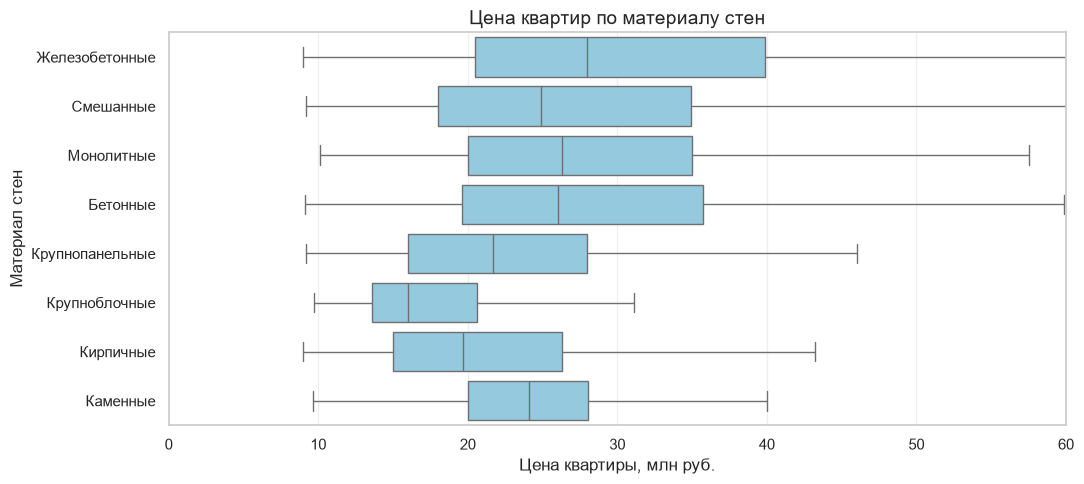

,median_price_mln_rub
wall_material,
Крупноблочные,16.00
Кирпичные,19.70
Крупнопанельные,21.70
Каменные,24.11
Смешанные,24.90
Бетонные,26.01
Монолитные,26.30
Железобетонные,28.00


In [5]:
# Словарь соответствия кода материала стен его названию
WALL_MATERIAL_NAMES = {
    '61001001000': 'Каменные',
    '61001001001': 'Кирпичные',
    '61001003000': 'Смешанные',
    '61001006000': 'Бетонные',
    '61001006001': 'Монолитные',
    '61001007000': 'Железобетонные',
    '61001007001': 'Крупнопанельные',
    '61001007004': 'Крупноблочные',
}
plot_df = df.dropna(subset=['wall_material_code', 'price']).copy()
plot_df['price_mln'] = plot_df['price'] / 1_000_000

plot_df['wall_material'] = plot_df['wall_material_code'].map(WALL_MATERIAL_NAMES).fillna('Прочие')
median_prices = plot_df.groupby('wall_material')['price_mln'].median().sort_values()

if not median_prices.empty:
    plt.figure(figsize=(11, max(5, 0.35 * len(median_prices))))
    ax = sns.boxplot(data=plot_df, y='wall_material', x='price_mln', color='skyblue', showfliers=False)
    plt.title('Цена квартир по материалу стен', fontsize=14)
    plt.xlabel('Цена квартиры, млн руб.')
    plt.ylabel('Материал стен')
    ax.set_xlim(0, 60)  # шкала цены — до 60 млн руб.
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    display(median_prices.rename('median_price_mln_rub').round(2).to_frame())
else:
    print('Нет данных для графика по материалу стен.')

### Цена квартиры в зависимости от района

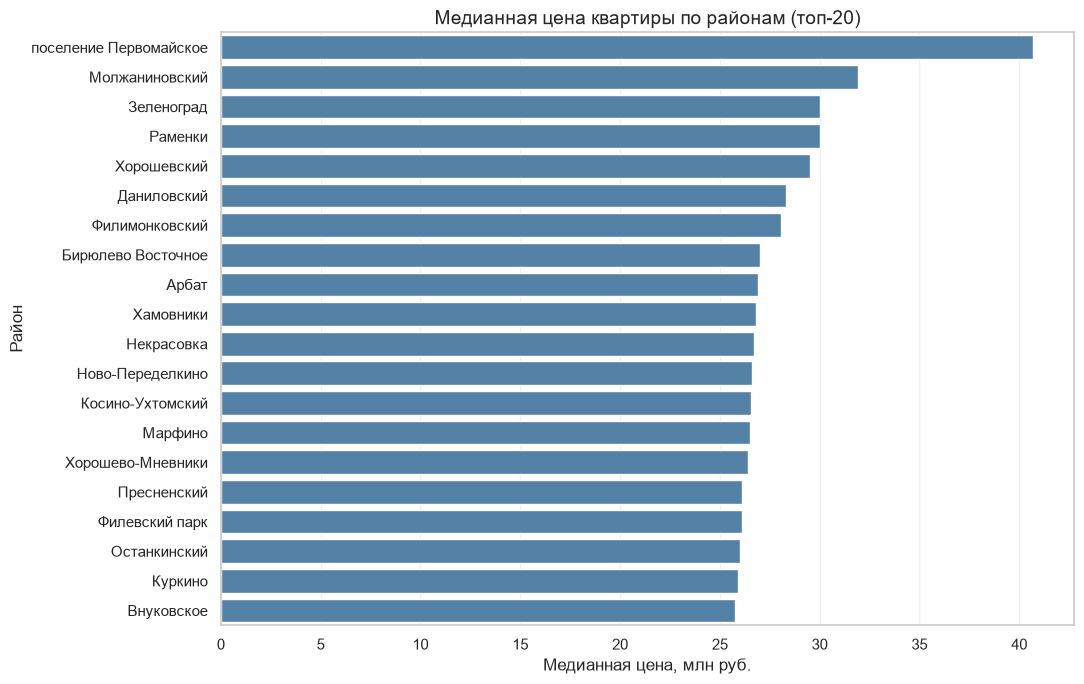

,median_price_mln_rub,object_count
district,,
поселение Первомайское,40.71,58
Молжаниновский,31.92,226
Зеленоград,30.00,1
Раменки,30.00,2160
Хорошевский,29.50,974
Даниловский,28.30,1559
Филимонковский,28.09,394
Бирюлево Восточное,27.00,464
Арбат,26.90,122


In [6]:
# Медианная цена по районам (в млн рублей)
plot_df = df.dropna(subset=['district', 'price']).copy()

stats = (
    plot_df.groupby('district')['price']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .head(20)
)

# Переводим медианную цену из рублей в млн рублей
stats['median'] = stats['median'] / 1_000_000

plt.figure(figsize=(11, max(5, 0.35 * len(stats))))

ax = sns.barplot(
    x=stats['median'].values,
    y=stats.index.astype(str),
    color='steelblue'
)

plt.title('Медианная цена квартиры по районам (топ-20)', fontsize=14)
plt.xlabel('Медианная цена, млн руб.')
plt.ylabel('Район')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(
    stats.rename(columns={
        'median': 'median_price_mln_rub',
        'count': 'object_count'
    }).round({'median_price_mln_rub': 2})
)

### Цена квартиры в зависимости от площади

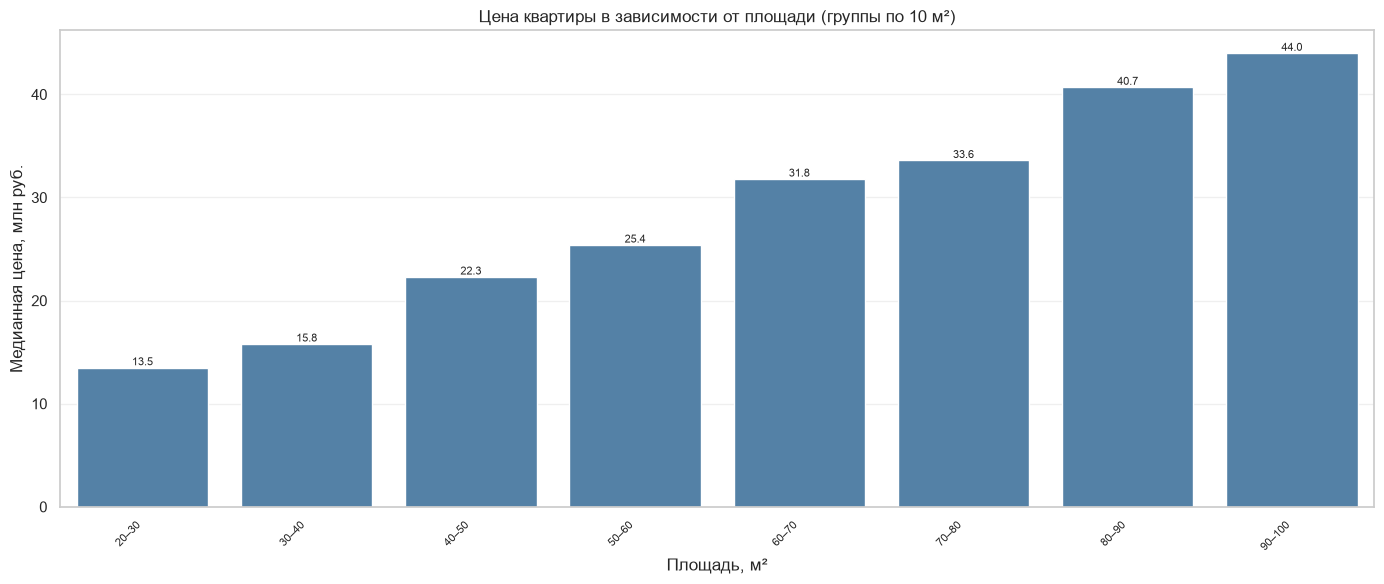

In [7]:
# Делим площадь на группы по 10 м² (цена — в млн руб.)
plot_df = df.dropna(subset=['area', 'price']).copy()
if plot_df['area'].nunique() >= 2:
    # Интервалы по 10 м²
    bins = list(range(0, 301, 10))
    plot_df['area_category'] = pd.cut(plot_df['area'], bins=bins)
    stats = plot_df.groupby('area_category', observed=True)['price'].median() / 1_000_000
    stats = stats.dropna()
    x_labels = [f'{int(interval.left)}–{int(interval.right)}' for interval in stats.index]

    plt.figure(figsize=(14, 6))
    ax = sns.barplot(x=x_labels, y=stats.values, color='steelblue')
    plt.title('Цена квартиры в зависимости от площади (группы по 10 м²)')
    plt.xlabel('Площадь, м²')
    plt.ylabel('Медианная цена, млн руб.')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.1f}', ha='center', va='bottom', fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print('Недостаточно различных значений площади для построения групп.')


### Стоимость квартир в зависимости от этажа

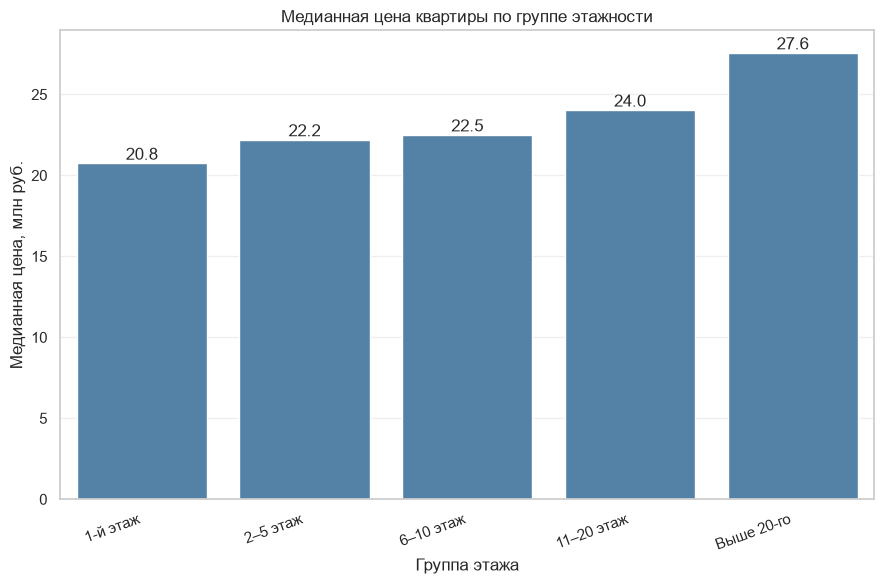

In [8]:

plot_df = df.dropna(subset=['floor', 'price']).copy()
plot_df['floor_group'] = pd.cut(
    plot_df['floor'], bins=[0, 1, 5, 10, 20, np.inf],
    labels=['1-й этаж', '2–5 этаж', '6–10 этаж', '11–20 этаж', 'Выше 20-го'],
    include_lowest=True
)
stats = plot_df.groupby('floor_group', observed=True)['price'].median() / 1_000_000

if not stats.empty:
    plt.figure(figsize=(9, 6))
    ax = sns.barplot(x=stats.index.astype(str), y=stats.values, color='steelblue')
    plt.title('Медианная цена квартиры по группе этажности')
    plt.xlabel('Группа этажа')
    plt.ylabel('Медианная цена, млн руб.')
    plt.xticks(rotation=20, ha='right')
    plt.grid(axis='y', alpha=0.3)
    for i, value in enumerate(stats.values):
        ax.text(i, value, f'{value:,.1f}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
else:
    print('Нет данных для анализа этажа.')


### Корреляционный анализ

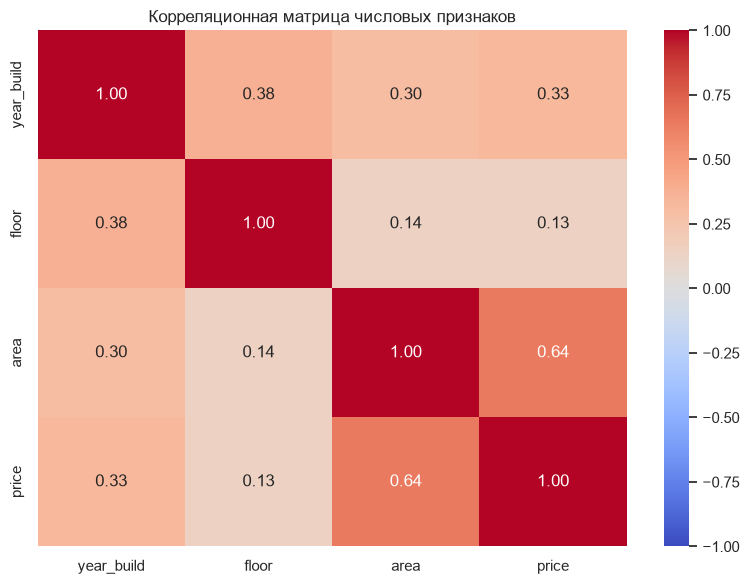

Корреляция признаков с целевой переменной price:
price         1.000
area          0.645
year_build    0.331
floor         0.133
Name: price, dtype: float64


In [9]:
# Для корреляции используем числовые признаки и целевую переменную
numeric_cols = ['year_build', 'floor', 'area', 'price']
df_corr = df[numeric_cols].copy()
corr_matrix = df_corr.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

print('Корреляция признаков с целевой переменной price:')
print(corr_matrix['price'].sort_values(ascending=False).round(3))


## 2. Формирование выборки для моделирования

Для всех моделей используется единый набор сделок после последовательного отсечения 3σ по цене квартиры и цене за м². Отбор выполняется до разделения по годам, как в v6.

Отбор использует целевые значения всех годов, включая 2026; поэтому тестовые метрики характеризуют **условную точность на отфильтрованной выборке**, а не качество оценки всех исходных сделок.


In [10]:
import re

CAT_COLS = ['region', 'district', 'street', 'wall_material_code']
NUM_COLS = ['year_build', 'floor', 'area']
FEATURE_COLS = CAT_COLS + NUM_COLS + ['period_year']
RANDOM_STATE = 42
FORECAST_N = 5
BUNDLE_PATH = Path('moscow_apartment_forecast_research_v9_3sigma.joblib')

def normalize_text(value):
    if pd.isna(value) or not str(value).strip():
        return '_неизвестно_'
    return re.sub(r'\s+', ' ', str(value).strip().lower().replace('ё','е'))

model_df = model_source.copy()
model_df['_source_id'] = model_df.index.astype(int)
for col in CAT_COLS:
    model_df[col] = model_df[col].map(normalize_text)
model_df['wall_material_code'] = model_df['wall_material_code'].str.replace(r'\.0+$','',regex=True)
for col in NUM_COLS + ['price']:
    model_df[col] = pd.to_numeric(model_df[col], errors='coerce')
model_df = model_df.dropna(subset=NUM_COLS + ['price','period_year']).copy()
model_df = model_df[
    model_df['period_year'].between(2023,2026) &
    model_df['year_build'].between(1800,2027) &
    (model_df['year_build'] <= model_df['period_year'] + 1) &
    model_df['floor'].between(1,100) &
    model_df['area'].between(25,400) &
    model_df['price'].between(7_000_000,1_000_000_000)
].copy()
model_df['price_per_sqm'] = model_df['price'] / model_df['area']
model_df = model_df[model_df['price_per_sqm'].between(50_000,15_000_000)].copy()
model_df['period_year'] = model_df['period_year'].astype(int)
model_df = model_df.sort_values('period_start_date').reset_index(drop=True)
assert {2023,2024,2025,2026}.issubset(set(model_df.period_year.unique())), 'Требуются сделки за 2023–2026 годы.'
print('Объектов для моделирования:', len(model_df))
display(model_df.groupby('period_year').agg(
    Сделок=('price','size'),
    Медианная_цена_млн=('price',lambda s:s.median()/1e6),
    Последняя_дата=('period_start_date','max')
))
display(pd.crosstab(model_df['period_start_date'].dt.month,model_df['period_year']).rename_axis('Месяц'))

Объектов для моделирования: 60289


,Сделок,Медианная_цена_млн,Последняя_дата
period_year,,,
2023,2999,23.53861,2023-12-28
2024,18148,23.60368,2024-10-01
2025,23702,23.50000,2025-10-01
2026,15440,22.00000,2026-04-01


period_year,2023,2024,2025,2026
Месяц,,,,
1,291,3524,4839,6709
2,256,0,0,0
3,175,0,0,0
4,232,4472,4890,8731
5,246,0,0,0
6,204,0,0,0
7,239,3738,5895,0
8,295,0,0,0
9,275,0,0,0


## 3. Регрессионные модели

Целевая переменная — логарифм цены за м². Прогноз приводится к полной стоимости квартиры. Категориальные признаки сохраняют географическую иерархию. Преобразования признаков выполняются только по обучающей части каждого временного разбиения.

In [11]:
from sklearn.linear_model import Ridge
from sklearn.feature_extraction import DictVectorizer
from sklearn.ensemble import HistGradientBoostingRegressor
from catboost import CatBoostRegressor

TIME_CENTER = 2024.5
MIN_STREET_TOTAL, MIN_STREET_PER_YEAR = 20, 5
MIN_DISTRICT_TOTAL, MIN_DISTRICT_PER_YEAR = 15, 3
MODEL_NAMES = {
    'ridge_static':'Статическая гедоническая Ridge',
    'ridge_time':'Динамическая гедоническая Ridge',
    'hgb':'HistGradientBoosting',
    'cat':'CatBoost'
}

def district_key(r):
    return f"{r['region']} | {r['district']}"

def street_key(r):
    return f"{r['region']} | {r['district']} | {r['street']}"

def supported_keys(frame, key_func, minimum_total, minimum_year):
    keys=[key_func(row) for row in frame[CAT_COLS].to_dict('records')]
    count=pd.crosstab(pd.Series(keys, index=frame.index), frame['period_year'])
    keep=(count.sum(axis=1)>=minimum_total) & ((count>=minimum_year).sum(axis=1)>=2)
    return set(count.index[keep])

def make_support(frame):
    return {
        'district_trends':supported_keys(frame,district_key,MIN_DISTRICT_TOTAL,MIN_DISTRICT_PER_YEAR),
        'street_trends':supported_keys(frame,street_key,MIN_STREET_TOTAL,MIN_STREET_PER_YEAR)
    }

def record_features(row, support, with_time=True, trend_scale=1.0):
    region=str(row['region']); wall=str(row['wall_material_code'])
    dist=district_key(row); street=street_key(row)
    log_area=np.log(float(row['area'])/50.0)
    floor=(float(row['floor'])-7)/12.0
    build=(float(row['year_build'])-1985)/40.0
    numeric={'log_area':log_area,'log_area_sq':log_area**2,
             'floor':floor,'floor_sq':floor**2,'build':build,'build_sq':build**2}
    level={'region='+region:1.,'district='+dist:1.,'street='+street:1.,'wall='+wall:1.,**numeric}
    features={'L:'+k:v for k,v in level.items()}
    if with_time:
        slope={'global':1.,'region='+region:1.,'wall='+wall:1.,**numeric}
        if dist in support['district_trends']:
            slope['district='+dist]=1.
        if street in support['street_trends']:
            slope['street='+street]=1.
        t=(float(row['period_year'])-TIME_CENTER)*float(trend_scale)
        features.update({'T:'+k:t*v for k,v in slope.items()})
    return features

def metrics(y, pred):
    y=np.asarray(y,float); pred=np.asarray(pred,float)
    mae=float(mean_absolute_error(y,pred)/1e6)
    rmse=float(np.sqrt(mean_squared_error(y,pred))/1e6)
    mape=float(np.mean(np.abs(y-pred)/y)*100)
    return {'MAE, млн ₽':mae,'RMSE, млн ₽':rmse,'R²':float(r2_score(y,pred)),
            'MAPE, %':mape,'Точность, %':100-mape}

class ApartmentEstimator(RegressorMixin, BaseEstimator):
    """Единый sklearn-совместимый интерфейс; преобразования обучаются внутри CV-fold."""
    def __init__(self, kind='ridge_time', alpha=100.0, trend_scale=1.0,
                 max_iter=180, max_leaf_nodes=31, min_samples_leaf=40,
                 learning_rate=0.07, l2_regularization=0.0,
                 iterations=240, depth=6, l2_leaf_reg=5.0,
                 random_strength=1.0, cat_feature_mode='native',
                 year_weighting='none', random_state=42, thread_count=3):
        self.kind=kind; self.alpha=alpha; self.trend_scale=trend_scale
        self.max_iter=max_iter; self.max_leaf_nodes=max_leaf_nodes
        self.min_samples_leaf=min_samples_leaf; self.learning_rate=learning_rate
        self.l2_regularization=l2_regularization; self.iterations=iterations
        self.depth=depth; self.l2_leaf_reg=l2_leaf_reg
        self.random_strength=random_strength; self.cat_feature_mode=cat_feature_mode
        self.year_weighting=year_weighting; self.random_state=random_state
        self.thread_count=thread_count

    def _boost_frame(self, X):
        frame=X.copy()
        frame['district_geo']=frame['region'].astype(str)+' | '+frame['district'].astype(str)
        frame['street_geo']=frame['district_geo']+' | '+frame['street'].astype(str)
        frame['building_age']=(frame['period_year']-frame['year_build']).clip(lower=0)
        frame['log_area']=np.log(frame['area'].astype(float)/50.)
        columns=['region','district_geo','street_geo','wall_material_code',
                 'year_build','floor','area','period_year','building_age','log_area']
        return frame[columns].copy()

    def _hgb_transform(self, X, fit=False):
        frame=self._boost_frame(X)
        cat_cols=['region','district_geo','street_geo','wall_material_code']
        num_cols=[c for c in frame if c not in cat_cols]
        if fit:
            self.hgb_allowed_={}
            for col,limit in [('region',100),('district_geo',180),('street_geo',200),('wall_material_code',100)]:
                self.hgb_allowed_[col]=set(frame[col].astype(str).value_counts().head(limit).index)
        for col in cat_cols:
            frame[col]=frame[col].astype(str).where(frame[col].isin(self.hgb_allowed_[col]),'_прочее_')
        if fit:
            self.encoder_=OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1)
            cats=self.encoder_.fit_transform(frame[cat_cols])
        else:
            cats=self.encoder_.transform(frame[cat_cols])
        nums=frame[num_cols].to_numpy(dtype=float)
        return np.column_stack([cats,nums])

    def _cat_frame(self, X):
        if self.cat_feature_mode == 'native':
            frame=X[FEATURE_COLS].copy()
            cat_cols=CAT_COLS
        elif self.cat_feature_mode == 'extended':
            frame=self._boost_frame(X)
            cat_cols=['region','district_geo','street_geo','wall_material_code']
        else:
            raise ValueError('Неизвестный способ кодирования CatBoost')
        for col in cat_cols:
            frame[col]=frame[col].astype(str)
        return frame,cat_cols

    def fit(self, X, y):
        X=X.copy().reset_index(drop=True)
        y=np.asarray(y,dtype=float)
        target=np.log(y/X['area'].to_numpy(dtype=float))
        counts=X['period_year'].value_counts(); n=len(X); years=len(counts)
        weights=X['period_year'].map(lambda v:n/(years*counts.loc[v])).to_numpy(float)
        boost_weights=weights if self.year_weighting=='balanced' else None
        if self.kind in ('ridge_static','ridge_time'):
            self.support_=make_support(X) if self.kind=='ridge_time' else {'district_trends':set(),'street_trends':set()}
            self.with_time_=self.kind=='ridge_time'
            recs=[record_features(r,self.support_,self.with_time_,self.trend_scale)
                  for r in X[FEATURE_COLS].to_dict('records')]
            self.vectorizer_=DictVectorizer(sparse=True)
            matrix=self.vectorizer_.fit_transform(recs)
            self.model_=Ridge(alpha=float(self.alpha),solver='lsqr',fit_intercept=True,tol=1e-5)
            self.model_.fit(matrix,target,sample_weight=weights)
        elif self.kind=='hgb':
            matrix=self._hgb_transform(X,fit=True)
            self.model_=HistGradientBoostingRegressor(
                max_iter=int(self.max_iter),max_leaf_nodes=int(self.max_leaf_nodes),
                min_samples_leaf=int(self.min_samples_leaf),learning_rate=float(self.learning_rate),
                l2_regularization=float(self.l2_regularization),
                categorical_features=[True,True,True,True,False,False,False,False,False,False],
                early_stopping=False,random_state=int(self.random_state)
            )
            self.model_.fit(matrix,target,sample_weight=boost_weights)
        elif self.kind=='cat':
            frame,cat_cols=self._cat_frame(X)
            self.model_=CatBoostRegressor(
                iterations=int(self.iterations),depth=int(self.depth),
                learning_rate=float(self.learning_rate),l2_leaf_reg=float(self.l2_leaf_reg),
                random_strength=float(self.random_strength),
                loss_function='RMSE',random_seed=int(self.random_state),
                verbose=False,thread_count=int(self.thread_count),allow_writing_files=False
            )
            self.model_.fit(frame,target,cat_features=cat_cols,sample_weight=boost_weights)
        else:
            raise ValueError('Неизвестная модель '+str(self.kind))
        self.is_fitted_=True
        return self

    def predict(self, X):
        check_is_fitted(self,'is_fitted_')
        X=X.copy().reset_index(drop=True)
        if self.kind in ('ridge_static','ridge_time'):
            records=[record_features(r,self.support_,self.with_time_,self.trend_scale)
                     for r in X[FEATURE_COLS].to_dict('records')]
            mat=self.vectorizer_.transform(records)
            log_ppsm=self.model_.predict(mat)
        elif self.kind=='hgb':
            log_ppsm=self.model_.predict(self._hgb_transform(X,fit=False))
        else:
            frame,_=self._cat_frame(X)
            log_ppsm=self.model_.predict(frame)
        result=np.exp(log_ppsm)*X['area'].to_numpy(dtype=float)
        if not np.isfinite(result).all():
            raise ValueError('Получены нечисловые прогнозы; проверьте диапазон признаков')
        return result

## 4. Хронологическая валидация

Одинаковые временные интервалы применяются ко всем моделям. Гиперпараметры выбираются без использования сделок 2026 года; предварительный отбор 3σ выполняется по всей совокупности, как в v6.


In [12]:
# Вычислительный бюджет для ноутбука: при необходимости увеличьте значения после первого запуска.
CV_MAX_FOLDS = 2
# 12 испытаний для каждого бустинга; значение можно уменьшить до 8 при ограниченных ресурсах.
COARSE_RANDOM_TRIALS = 12
SEARCH_N_JOBS = 1
CATBOOST_THREADS = 3

train_df=model_df[model_df.period_year<=2025].copy().reset_index(drop=True)
test_df=model_df[model_df.period_year==2026].copy().reset_index(drop=True)
X_train=train_df[FEATURE_COLS].copy(); y_train=train_df.price.to_numpy(float)
X_test=test_df[FEATURE_COLS].copy(); y_test=test_df.price.to_numpy(float)

# Последовательные шестимесячные контрольные интервалы.
intervals=[('2024-07-01','2025-01-01'),('2025-01-01','2025-07-01'),('2025-07-01','2026-01-01')]
folds=[]; fold_info=[]
for left,right in intervals:
    border=pd.Timestamp(left); end=pd.Timestamp(right)
    tr=np.where(train_df.period_start_date.to_numpy()<np.datetime64(border))[0]
    va=np.where((train_df.period_start_date.to_numpy()>=np.datetime64(border)) &
                (train_df.period_start_date.to_numpy()<np.datetime64(end)))[0]
    if len(tr)<100 or len(va)<30 or train_df.iloc[tr].period_year.nunique()<2:
        continue
    folds.append((tr,va))
    fold_info.append({'Обучение до':str(border.date()),'Валидация':str(border.date())+' — '+str((end-pd.Timedelta(days=1)).date()),
                      'Сделок в обучении':len(tr),'Сделок в валидации':len(va)})
folds=folds[-CV_MAX_FOLDS:];fold_info=fold_info[-CV_MAX_FOLDS:]
if len(folds)<2:
    raise ValueError('Нужно минимум два корректных временных окна. Проверьте наличие сделок в 2024–2025 годах.')
assert all(train_df.iloc[tr].period_start_date.max()<train_df.iloc[va].period_start_date.min() for tr,va in folds)
assert train_df.period_year.max()<test_df.period_year.min()
print('Хронологические разбиения для всех моделей:')
display(pd.DataFrame(fold_info))
print('Независимый тест:',len(test_df),'сделок за',test_df.period_start_date.min().date(),'—',test_df.period_start_date.max().date())

Хронологические разбиения для всех моделей:


,Обучение до,Валидация,Сделок в обучении,Сделок в валидации
0,2025-01-01,2025-01-01 — 2025-06-30,21147,9729
1,2025-07-01,2025-07-01 — 2025-12-31,30876,13973


Независимый тест: 15440 сделок за 2026-01-01 — 2026-04-01


## 5. Первичный подбор моделей

GridSearchCV — для статической и динамической Ridge; RandomizedSearchCV — для HistGradientBoosting и CatBoost. Исходная конфигурация CatBoost из v6 включена в сравнение.


In [13]:
from sklearn.model_selection import ParameterGrid

small_spaces={
    'ridge_static':{'alpha':[1.,5.,20.,50.,100.,300.,1000.]},
    'ridge_time':{'alpha':[2.,10.,50.,200.,700.], 'trend_scale':[0.75,1.0,1.25]},
    'hgb':{
        'max_iter':randint(260,701),
        'max_leaf_nodes':randint(16,65),
        'min_samples_leaf':randint(15,91),
        'learning_rate':loguniform(.03,.13),
        'l2_regularization':loguniform(.01,20.),
        'year_weighting':['none','balanced']
    },
    'cat':{
        'iterations':randint(320,751),
        'depth':randint(5,10),
        'learning_rate':loguniform(.035,.12),
        'l2_leaf_reg':loguniform(2.,14.),
        'random_strength':uniform(0.,1.4),
        'cat_feature_mode':['native'],
        'year_weighting':['none']
    }
}

def run_search(kind, stage, params, n_iter=None):
    estimator=ApartmentEstimator(kind=kind,random_state=RANDOM_STATE,thread_count=CATBOOST_THREADS)
    common=dict(estimator=estimator,scoring='neg_mean_absolute_error',cv=folds,
                n_jobs=SEARCH_N_JOBS,refit=True,error_score='raise',verbose=0,return_train_score=False)
    if n_iter is None:
        search=GridSearchCV(param_grid=params,**common)
    else:
        search=RandomizedSearchCV(param_distributions=params,n_iter=n_iter,random_state=RANDOM_STATE,**common)
    start=time.perf_counter()
    search.fit(X_train,y_train)
    print(f'{stage} | {MODEL_NAMES[kind]} | CV MAE = {-search.best_score_/1e6:.3f} млн ₽ | {time.perf_counter()-start:.1f} с')
    return search

screen_search={}
for kind in MODEL_NAMES:
    trials=COARSE_RANDOM_TRIALS if kind in ('hgb','cat') else None
    screen_search[kind]=run_search(kind,'Этап I',small_spaces[kind],n_iter=trials)

# Контроль воспроизводимости конфигурации v6: тот же состав исходных признаков,
# те же параметры CatBoost и отсутствие годовых весов.
CATBOOST_V6_PARAMS={
    'iterations':400,'depth':7,'learning_rate':0.055,
    'l2_leaf_reg':6.0,'random_strength':1.0,
    'cat_feature_mode':'native','year_weighting':'none'
}
cat_v6_reference_search=run_search('cat','Контроль v6',
    {k:[v] for k,v in CATBOOST_V6_PARAMS.items()})
if cat_v6_reference_search.best_score_ > screen_search['cat'].best_score_:
    screen_search['cat']=cat_v6_reference_search
    print('На этапе I для CatBoost принята исходная конфигурация v6.')

screening_table=pd.DataFrame([
    {'Модель':MODEL_NAMES[kind],'Алгоритм':kind,
     'CV MAE, млн ₽':-search.best_score_/1e6,
     'Наборов параметров':len(search.cv_results_['params']),
     'Параметры':str(search.best_params_)}
    for kind,search in screen_search.items()
]).sort_values('CV MAE, млн ₽').reset_index(drop=True)
screen_winner=str(screening_table.iloc[0]['Алгоритм'])
print('Предварительный победитель:',MODEL_NAMES[screen_winner])
display(screening_table.drop(columns=['Алгоритм']).round(3))

Этап I | Статическая гедоническая Ridge | CV MAE = 6.834 млн ₽ | 18.0 с
Этап I | Динамическая гедоническая Ridge | CV MAE = 6.955 млн ₽ | 75.4 с
Этап I | HistGradientBoosting | CV MAE = 6.374 млн ₽ | 60.2 с
Этап I | CatBoost | CV MAE = 6.366 млн ₽ | 758.5 с
Контроль v6 | CatBoost | CV MAE = 6.403 млн ₽ | 69.8 с
Предварительный победитель: CatBoost


,Модель,"CV MAE, млн ₽",Наборов параметров,Параметры
0,CatBoost,6.366,12,"{'cat_feature_mode': 'native', 'depth': 9, 'it..."
1,HistGradientBoosting,6.374,12,{'l2_regularization': np.float64(0.03273574371...
2,Статическая гедоническая Ridge,6.834,7,{'alpha': 5.0}
3,Динамическая гедоническая Ridge,6.955,15,"{'alpha': 200.0, 'trend_scale': 0.75}"


## 6. Углублённый подбор гиперпараметров

Локальный GridSearchCV проводится только для модели с минимальным валидационным MAE. Окончательная конфигурация выбирается по той же хронологической схеме.

In [14]:
def nearby_int(value, ratios, low=2, high=None):
    vals=[max(low,int(round(value*r))) for r in ratios]
    if high is not None:vals=[min(high,v) for v in vals]
    return sorted(set(vals))

def local_grid(kind, params):
    if kind=='ridge_static':
        return {'alpha':sorted(set(round(max(1e-4,params['alpha']*m),6) for m in [.3,.6,1.,1.5,3.]))}
    if kind=='ridge_time':
        return {'alpha':sorted(set(round(max(1e-4,params['alpha']*m),6) for m in [.6,1.,1.8])),
                'trend_scale':sorted(set(round(params['trend_scale']*m,4) for m in [.85,1.,1.15]))}
    if kind=='hgb':
        return {'max_iter':nearby_int(params['max_iter'],[.8,1.,1.2],low=100),
                'max_leaf_nodes':nearby_int(params['max_leaf_nodes'],[.85,1.15],low=8,high=150),
                'learning_rate':sorted(set(round(float(params['learning_rate'])*m,6) for m in [.82,1.12])),
                'min_samples_leaf':[int(params['min_samples_leaf'])],
                'l2_regularization':[float(params['l2_regularization'])],
                'year_weighting':[params['year_weighting']]}
    return {'iterations':nearby_int(params['iterations'],[.8,1.,1.2],low=150),
            'depth':sorted(set(max(4,min(10,int(params['depth']+d))) for d in [-1,1])),
            'learning_rate':sorted(set(round(float(params['learning_rate'])*m,6) for m in [.85,1.15])),
            'l2_leaf_reg':[float(params['l2_leaf_reg'])],
            'random_strength':[float(params['random_strength'])],
            'cat_feature_mode':[params['cat_feature_mode']],
            'year_weighting':[params['year_weighting']]}

refine_space=local_grid(screen_winner,screen_search[screen_winner].best_params_)
print('Модель для уточнения:',MODEL_NAMES[screen_winner])
print('Количество комбинаций:',len(list(ParameterGrid(refine_space))))
refined_search=run_search(screen_winner,'Этап II',refine_space)

if refined_search.best_score_ > screen_search[screen_winner].best_score_:
    final_winner_search=refined_search
    refinement_status='Параметры уточнены'
else:
    final_winner_search=screen_search[screen_winner]
    refinement_status='Сохранены параметры первого этапа'

selected_search={k:(final_winner_search if k==screen_winner else screen_search[k]) for k in MODEL_NAMES}
print(refinement_status)
print('Итоговые гиперпараметры:',final_winner_search.best_params_)
print('CV MAE до:',round(-screen_search[screen_winner].best_score_/1e6,4),'млн ₽')
print('CV MAE после:',round(-final_winner_search.best_score_/1e6,4),'млн ₽')

Модель для уточнения: CatBoost
Количество комбинаций: 12
Этап II | CatBoost | CV MAE = 6.350 млн ₽ | 1143.4 с
Параметры уточнены
Итоговые гиперпараметры: {'cat_feature_mode': 'native', 'depth': 10, 'iterations': 555, 'l2_leaf_reg': 2.0917992640459695, 'learning_rate': 0.056794, 'random_strength': 0.5598053604013576, 'year_weighting': 'none'}
CV MAE до: 6.3659 млн ₽
CV MAE после: 6.3496 млн ₽


## 7. Оценка на отложенных сделках 2026 года

Все модели обучаются на одинаковой отфильтрованной выборке 2023–2025 годов и проверяются на сделках 2026 года после того же отбора 3σ. Основная метрика ранжирования — MAE.


Лучший на независимом тесте по MAE: CatBoost
Выбранная по CV модель: CatBoost


,Место,Модель,Этап II,"CV MAE, млн ₽","MAE, млн ₽","RMSE, млн ₽",R²,"MAPE, %","Точность, %",Выбрана по CV
0,1,CatBoost,да,6.350,5.883,9.296,0.544,20.827,79.173,да
1,2,HistGradientBoosting,нет,6.374,5.897,9.286,0.545,20.861,79.139,нет
2,3,Статическая гедоническая Ridge,нет,6.834,6.273,9.775,0.495,22.573,77.427,нет
3,4,Динамическая гедоническая Ridge,нет,6.955,6.772,9.909,0.482,23.652,76.348,нет


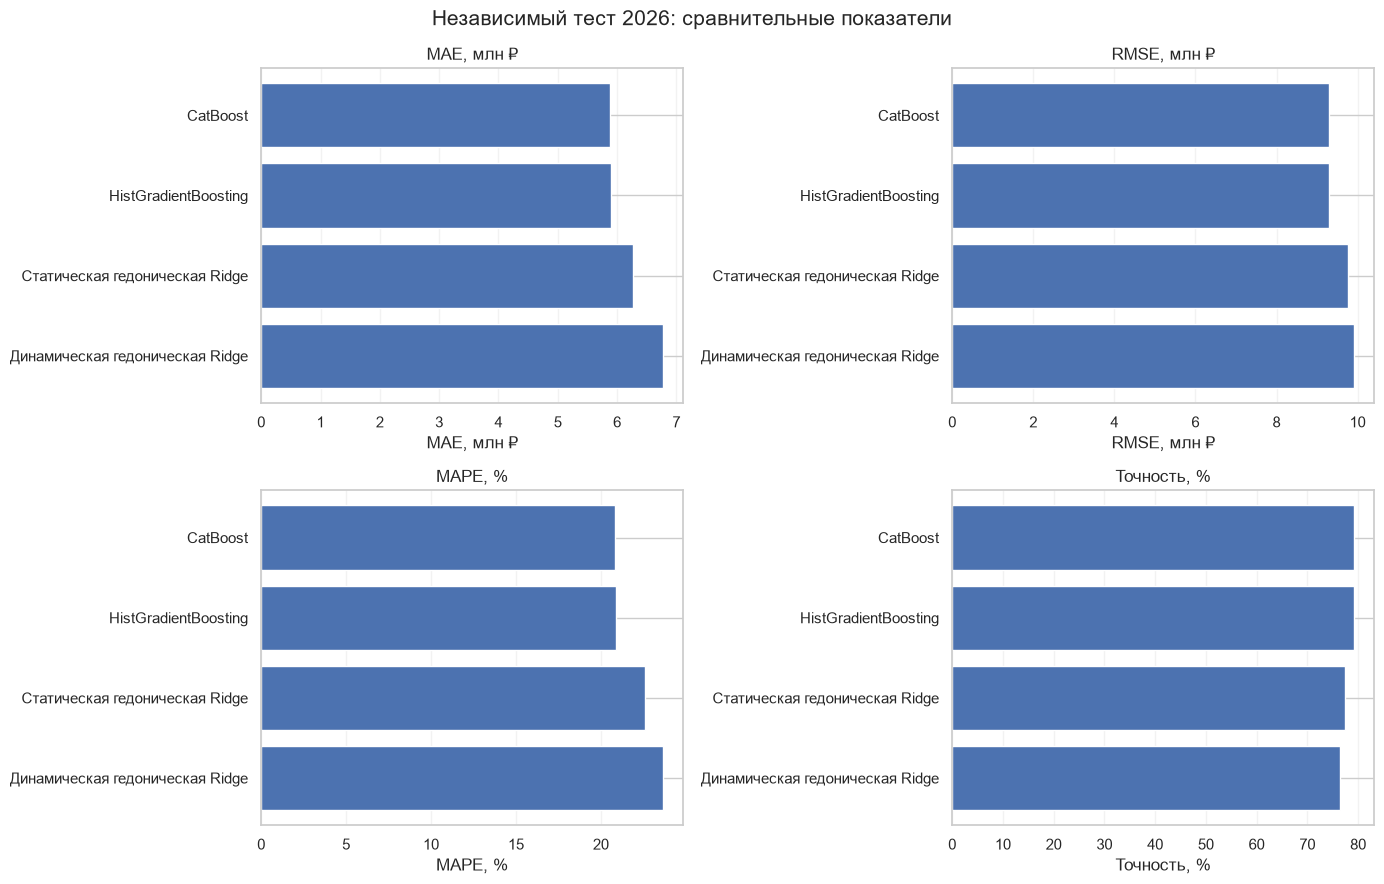

In [15]:
from collections import OrderedDict

fitted_test_models={kind:search.best_estimator_ for kind,search in selected_search.items()}
test_predictions={kind:model.predict(X_test) for kind,model in fitted_test_models.items()}
ranking=pd.DataFrame([
    {'Модель':MODEL_NAMES[kind], 'Алгоритм':kind,
     'Этап II':('да' if kind==screen_winner else 'нет'),
     'CV MAE, млн ₽':-selected_search[kind].best_score_/1e6,
     **metrics(y_test,test_predictions[kind])}
    for kind in MODEL_NAMES
]).sort_values('MAE, млн ₽',ascending=True).reset_index(drop=True)
ranking.insert(0,'Место',np.arange(1,len(ranking)+1))
ranking['Выбрана по CV']=ranking['Алгоритм'].eq(screen_winner).map({True:'да',False:'нет'})
print('Лучший на независимом тесте по MAE:',ranking.iloc[0]['Модель'])
print('Выбранная по CV модель:',MODEL_NAMES[screen_winner])
display(ranking.drop(columns=['Алгоритм']).round(3))

fig,axes=plt.subplots(2,2,figsize=(14,9))
for ax,key in zip(axes.flat,['MAE, млн ₽','RMSE, млн ₽','MAPE, %','Точность, %']):
    ax.barh(ranking['Модель'][::-1],ranking[key][::-1])
    ax.set(title=key,xlabel=key)
    ax.grid(axis='x',alpha=.25)
fig.suptitle('Независимый тест 2026: сравнительные показатели',fontsize=15)
plt.tight_layout();plt.show()

## 8. Оценка лучшей модели

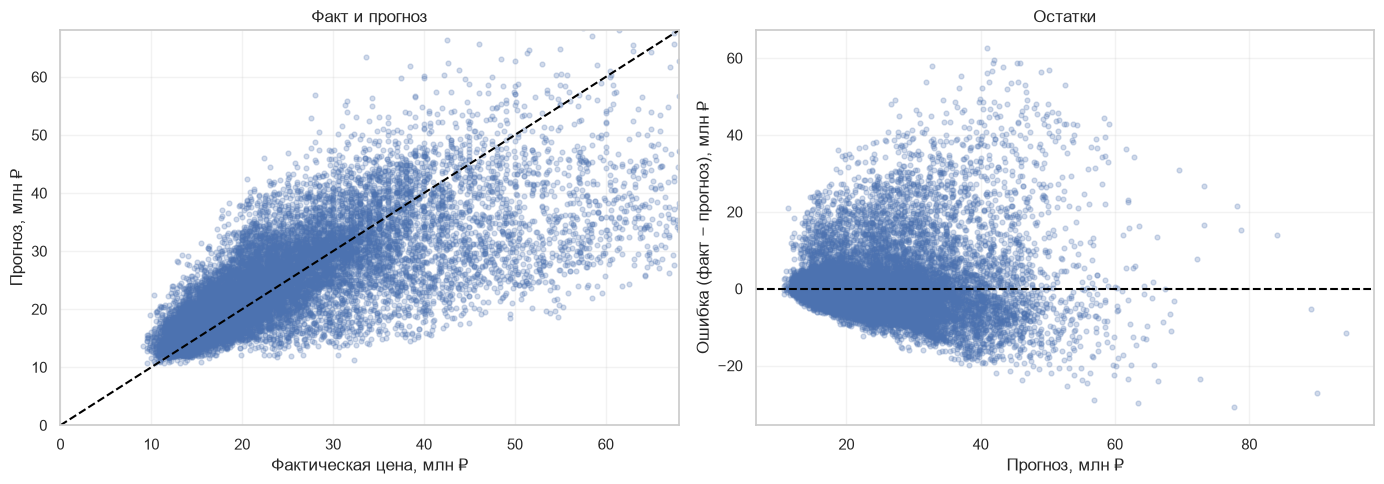

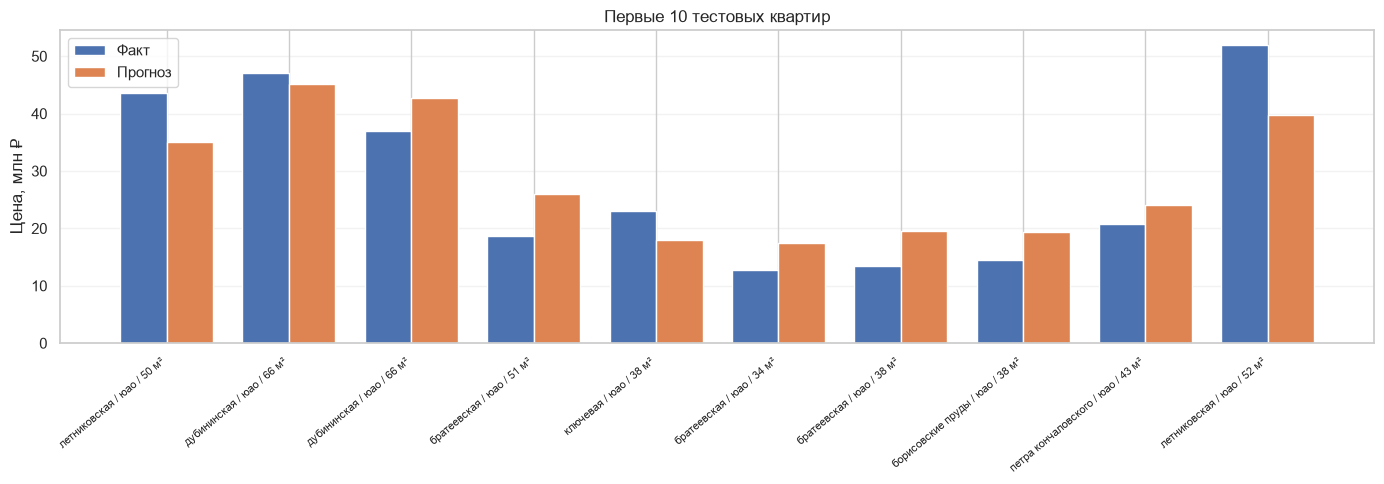

In [17]:
best_test_kind=str(ranking.iloc[0]['Алгоритм'])
best_model_name=MODEL_NAMES[best_test_kind]
actual_test=y_test.copy()
pred_test=test_predictions[best_test_kind]
test_year=2026
comparison=pd.DataFrame({'real_mln':actual_test/1e6,'predicted_mln':pred_test/1e6})
comparison['error_mln']=comparison['real_mln']-comparison['predicted_mln']
comparison['error_pct']=100*np.abs(comparison['error_mln'])/comparison['real_mln']

fig,axes=plt.subplots(1,2,figsize=(14,5))
q=float(np.quantile(np.r_[actual_test,pred_test]/1e6,.99))
axes[0].scatter(actual_test/1e6,pred_test/1e6,s=12,alpha=.25)
axes[0].plot([0,q],[0,q],'--',color='black')
axes[0].set(title='Факт и прогноз',xlabel='Фактическая цена, млн ₽',ylabel='Прогноз, млн ₽',xlim=(0,q),ylim=(0,q))
axes[1].scatter(pred_test/1e6,(actual_test-pred_test)/1e6,s=12,alpha=.25)
axes[1].axhline(0,linestyle='--',color='black')
axes[1].set(title='Остатки',xlabel='Прогноз, млн ₽',ylabel='Ошибка (факт − прогноз), млн ₽')
for ax in axes:ax.grid(alpha=.25)
plt.tight_layout();plt.show()

n=min(10,len(test_df)); rows=comparison.head(n)
labels=[f'{s} / {r} / {a:.0f} м²' for s,r,a in zip(test_df.street.head(n),test_df.region.head(n),test_df.area.head(n))]
x=np.arange(n)
fig,ax=plt.subplots(figsize=(14,5))
ax.bar(x-.19,rows.real_mln,.38,label='Факт')
ax.bar(x+.19,rows.predicted_mln,.38,label='Прогноз')
ax.set(title='Первые 10 тестовых квартир',ylabel='Цена, млн ₽',xticks=x,xticklabels=labels)
plt.setp(ax.get_xticklabels(),rotation=40,ha='right',fontsize=8)
ax.grid(axis='y',alpha=.25);ax.legend();plt.tight_layout();plt.show()

## 9. Финальное обучение и экспериментальная экстраполяция

Модель с минимальным CV MAE переобучается на отфильтрованной совокупности. Для исследования долгосрочной динамики отдельно сохраняется динамическая Ridge. Выбор модели для оценки стоимости и модель экстраполяции разграничены.


In [19]:
FINAL_BASE_YEAR=2026
FINAL_PRICE_MODEL=clone(selected_search[screen_winner].best_estimator_).fit(
    model_df[FEATURE_COLS],model_df.price.to_numpy(float))
TREND_TRAIN=model_df[model_df.period_year<=2025].copy()
trend_params=selected_search['ridge_time'].best_params_
FINAL_TREND_MODEL=ApartmentEstimator(kind='ridge_time',random_state=RANDOM_STATE,
                                     thread_count=CATBOOST_THREADS,**trend_params).fit(
    TREND_TRAIN[FEATURE_COLS],TREND_TRAIN.price.to_numpy(float))
MODEL_BUNDLE={
    'price_model':FINAL_PRICE_MODEL,
    'trend_model':FINAL_TREND_MODEL,
    'selected_model':MODEL_NAMES[screen_winner],
    'base_year':FINAL_BASE_YEAR,
    'source_file':DATA_PATH.name,
    'version':'research-v9-3sigma-before-comparison',
    'metrics_test_2026':ranking.drop(columns=['Алгоритм']).to_dict('records'),
    'price_model_params':selected_search[screen_winner].best_params_,
    'trend_model_params':trend_params,
}
joblib.dump(MODEL_BUNDLE,BUNDLE_PATH,compress=3)
LOADED_BUNDLE=joblib.load(BUNDLE_PATH)
assert np.allclose(FINAL_PRICE_MODEL.predict(X_test.head(5)),
                   LOADED_BUNDLE['price_model'].predict(X_test.head(5)))
print('Итоговая модель стоимости:',MODEL_NAMES[screen_winner])
print('Отдельная модель экстраполяции: динамическая Ridge')
print('Победитель по CV:',MODEL_NAMES[screen_winner])

Итоговая модель стоимости: CatBoost
Отдельная модель экстраполяции: динамическая Ridge
Победитель по CV: CatBoost


## 11. Анализ временной динамики прогнозируемой стоимости

Динамические сценарии до 2031 года строятся отдельно по гедонической Ridge с временными взаимодействиями. Их результаты не заменяют независимую оценку победившей модели и не подтверждают точность пятилетнего прогноза.

In [20]:
def apartment_row(apartment,year):
    missing=set(CAT_COLS+NUM_COLS)-set(apartment)
    if missing:raise ValueError('Не заданы признаки: '+str(sorted(missing)))
    row={k:normalize_text(apartment[k]) for k in CAT_COLS}
    row['wall_material_code']=row['wall_material_code'].removesuffix('.0')
    row.update({k:float(apartment[k]) for k in NUM_COLS})
    row['period_year']=int(year)
    if not (25<=row['area']<=400 and 1<=row['floor']<=100 and 1800<=row['year_build']<=year+1):
        raise ValueError('Параметры квартиры за пределами обучающей выборки')
    return pd.DataFrame([row])[FEATURE_COLS]

def forecast_apartment(apartment,n_years=5,bundle=None,base_year=None):
    bundle=LOADED_BUNDLE if bundle is None else bundle
    base_year=bundle['base_year'] if base_year is None else int(base_year)
    model=bundle['trend_model']
    years=np.arange(base_year,base_year+n_years+1)
    prices=np.array([model.predict(apartment_row(apartment,year))[0] for year in years])
    if not np.isfinite(prices).all() or (prices<=0).any():
        raise ValueError('Некорректная последовательность цен')
    return pd.DataFrame({'Год':years,'Прогноз цены, млн руб.':prices/1e6,
        'Годовой рост, %':np.r_[np.nan,(prices[1:]/prices[:-1]-1)*100],
        'Рост от базового года, %':(prices/prices[0]-1)*100})

APARTMENT_A={'region':'ВАО','district':'Восточное Измайлово','street':'Первомайская',
    'wall_material_code':'61001007001','year_build':1980,'floor':7,'area':54.0}
APARTMENT_B={'region':'ЦАО','district':'Тверской','street':'Тверская',
    'wall_material_code':'61001007001','year_build':2005,'floor':3,'area':68.0}

## 12. Вклад характеристик в прогнозируемый временной тренд

Разложение взаимодействий `год × признак` временной Ridge. Проверяется совпадение суммы вкладов с темпом изменения предсказанной цены.

In [21]:
def trend_decomposition(model,apartment,base_year=FINAL_BASE_YEAR):
    row=apartment_row(apartment,base_year).iloc[0].to_dict()
    feats=record_features(row,model.support_,with_time=True,trend_scale=model.trend_scale)
    coef=dict(zip(model.vectorizer_.get_feature_names_out(),model.model_.coef_))
    denom=float(base_year-TIME_CENTER)*float(model.trend_scale)
    parts=[(k[2:],float(v/denom)*float(coef.get(k,0))*float(model.trend_scale))
           for k,v in feats.items() if k.startswith('T:')]
    total=sum(v for _,v in parts)
    year_0=model.predict(apartment_row(apartment,base_year))[0]
    year_1=model.predict(apartment_row(apartment,base_year+1))[0]
    assert np.isclose(total,np.log(year_1/year_0),atol=1e-6)
    return pd.DataFrame(parts,columns=['Временной признак','Вклад в log(цена/м²) за год']).sort_values(
        'Вклад в log(цена/м²) за год',key=abs,ascending=False)

for label,apt in [('Первомайская',APARTMENT_A),('Тверская',APARTMENT_B)]:
    desc=trend_decomposition(FINAL_TREND_MODEL,apt)
    print(label,'| выученный годовой рост:',round(forecast_apartment(apt,1).iloc[1]['Годовой рост, %'],3),'%')
    display(desc.head(12).round(5))

Первомайская | выученный годовой рост: 3.842 %


,Временной признак,Вклад в log(цена/м²) за год
3,log_area,0.01932
0,global,0.01163
2,wall=61001007001,0.01005
7,build,0.00568
1,region=вао,-0.00526
9,district=вао | восточное измайлово,-0.00417
8,build_sq,0.00102
4,log_area_sq,-0.00056
5,floor,-0.00000
6,floor_sq,-0.00000


Тверская | выученный годовой рост: 10.044 %


,Временной признак,Вклад в log(цена/м²) за год
3,log_area,0.07717
7,build,-0.02271
1,region=цао,0.01702
8,build_sq,0.01630
0,global,0.01163
2,wall=61001007001,0.01005
4,log_area_sq,-0.00890
9,district=цао | тверской,-0.00738
5,floor,0.00288
6,floor_sq,-0.00034


## 13. Однофакторный анализ потенциала роста

Контролируемые сравнения влияния округа, района, материала стен и этажа. Остальные характеристики квартиры фиксируются.

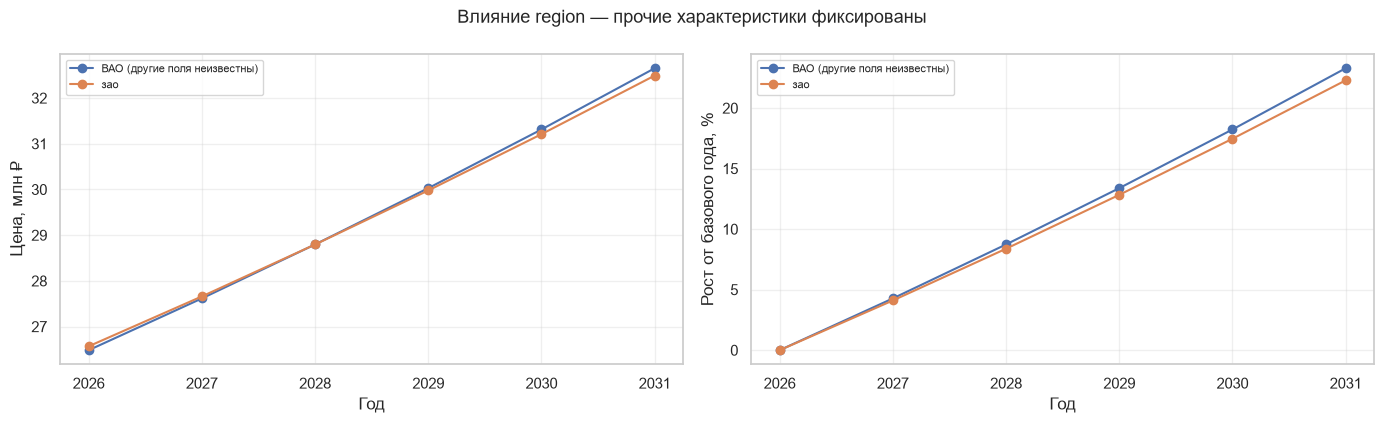

,Вариант,"Цена старта, млн ₽","Годовой рост, %","Рост за N лет, %"
0,ВАО (другие поля неизвестны),26.484,4.276,23.289
1,зао,26.569,4.107,22.290


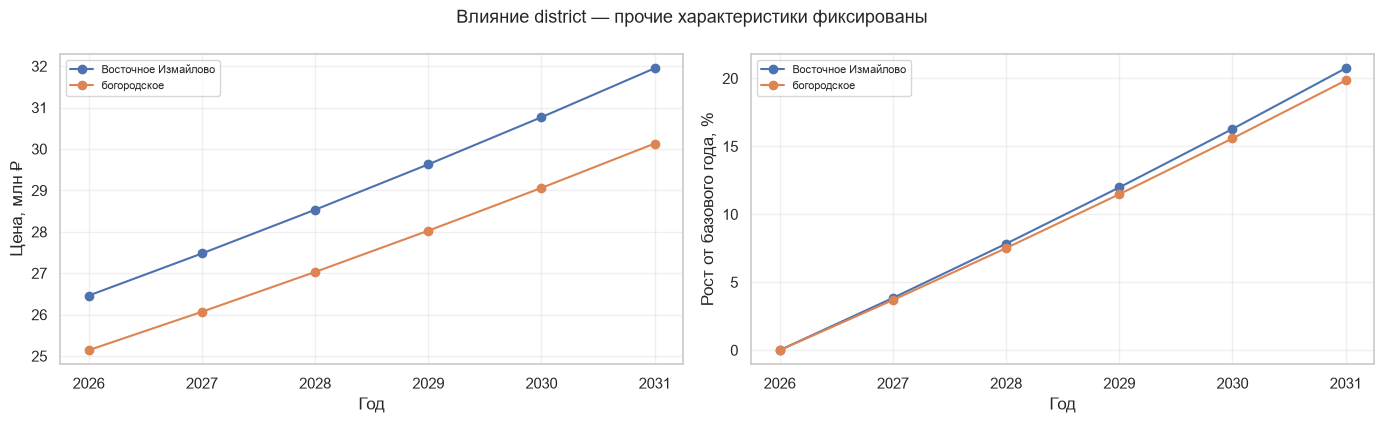

,Вариант,"Цена старта, млн ₽","Годовой рост, %","Рост за N лет, %"
0,Восточное Измайлово,26.460,3.842,20.744
1,богородское,25.142,3.687,19.847


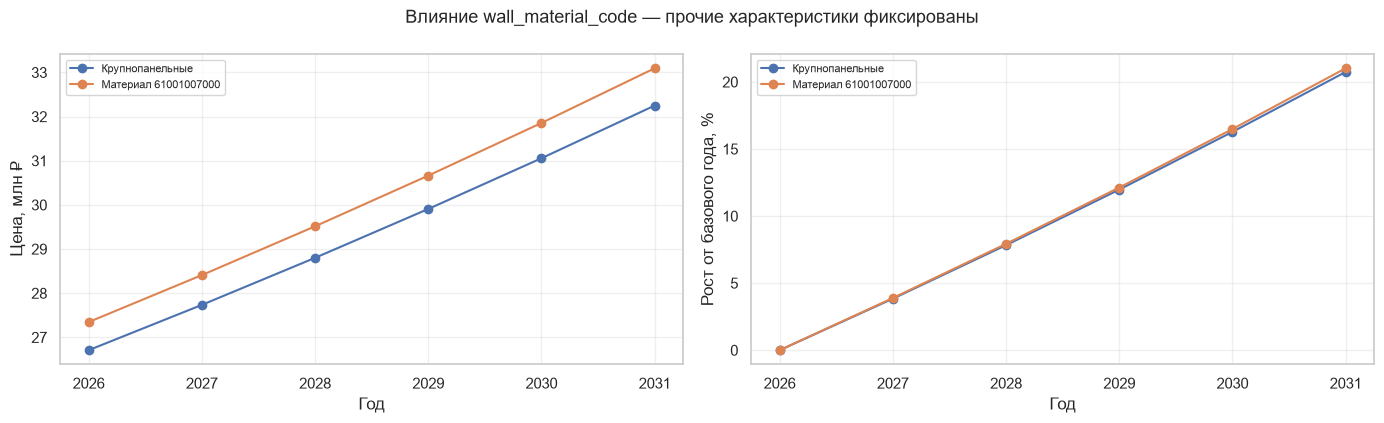

,Вариант,"Цена старта, млн ₽","Годовой рост, %","Рост за N лет, %"
0,Крупнопанельные,26.709,3.842,20.744
1,Материал 61001007000,27.346,3.889,21.020


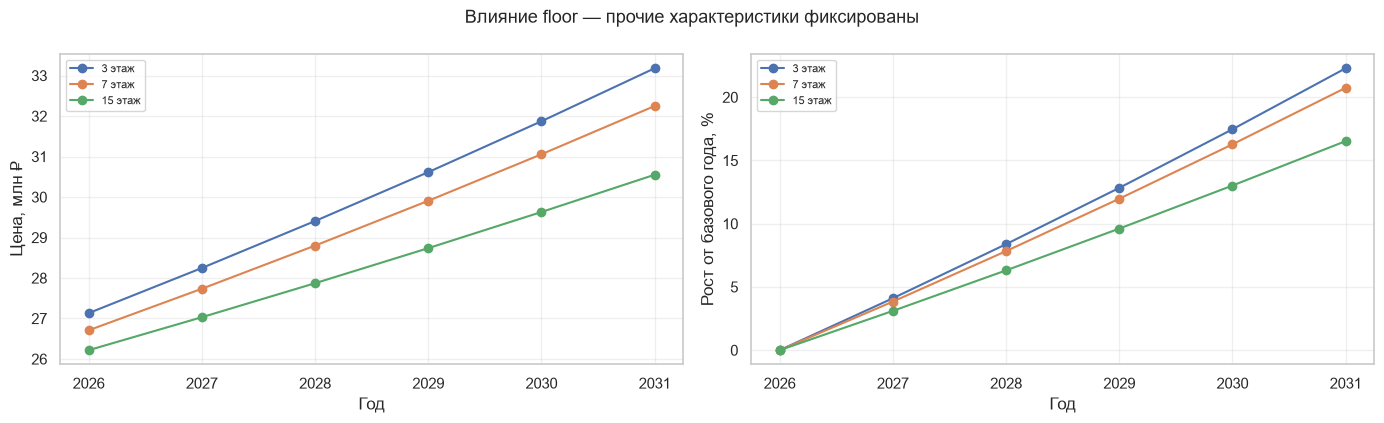

,Вариант,"Цена старта, млн ₽","Годовой рост, %","Рост за N лет, %"
0,3 этаж,27.133,4.107,22.290
1,7 этаж,26.709,3.842,20.744
2,15 этаж,26.217,3.107,16.529


,Вариант,"Цена старта, млн ₽","Годовой рост, %","Рост за N лет, %"
0,3 этаж,27.133270,4.106631,22.290287
1,7 этаж,26.709070,3.842091,20.744434
2,15 этаж,26.217494,3.106730,16.529281


In [22]:
def compare_counterfactuals(title, variants, n_years=FORECAST_N):
    if len(variants)<2:
        print('Пропуск',title,'— недостаточно наблюдаемых вариантов')
        return None
    fig,axes=plt.subplots(1,2,figsize=(14,4.3))
    rows=[]
    for name,apt in variants:
        path=forecast_apartment(apt,n_years)
        axes[0].plot(path['Год'],path['Прогноз цены, млн руб.'],marker='o',label=name)
        axes[1].plot(path['Год'],path['Рост от базового года, %'],marker='o',label=name)
        rows.append({'Вариант':name,'Цена старта, млн ₽':path.iloc[0]['Прогноз цены, млн руб.'],
                     'Годовой рост, %':path.iloc[1]['Годовой рост, %'],
                     'Рост за N лет, %':path.iloc[-1]['Рост от базового года, %']})
    for ax in axes:
        ax.set_xlabel('Год');ax.grid(alpha=.3);ax.legend(fontsize=8)
    axes[0].set_ylabel('Цена, млн ₽');axes[1].set_ylabel('Рост от базового года, %')
    fig.suptitle(title+' — прочие характеристики фиксированы',fontsize=13)
    fig.tight_layout();plt.show()
    result=pd.DataFrame(rows);display(result.round(3));return result

base=dict(APARTMENT_A)
# Фиксируем доступные уровни по фактическому обучающему набору.
regions=sorted(model_df['region'].dropna().unique())
other_region=next((r for r in regions if r!=normalize_text(base['region'])),None)
if other_region:
    first={**base,'district':'_неизвестно_','street':'_неизвестно_'}
    second={**first,'region':other_region}
    compare_counterfactuals('Влияние region', [('ВАО (другие поля неизвестны)',first),(other_region,second)])

base_region=normalize_text(base['region'])
base_district=normalize_text(base['district'])
others=model_df.loc[(model_df.region==base_region)&(model_df.district!=base_district),'district'].value_counts()
if len(others):
    first={**base,'street':'_неизвестно_'}
    second={**first,'district':str(others.index[0])}
    compare_counterfactuals('Влияние district',[(base['district'],first),(str(others.index[0]),second)])
else: print('Нет второго района для контролируемого сравнения district в выбранном округе.')

walls=[str(x) for x in model_df.wall_material_code.value_counts().index if x!=normalize_text(base['wall_material_code'])]
if walls:
    compare_counterfactuals('Влияние wall_material_code',
        [('Крупнопанельные',base),('Материал '+walls[0],{**base,'wall_material_code':walls[0]})])
compare_counterfactuals('Влияние floor',[(str(v)+' этаж',{**base,'floor':v}) for v in [3,7,15]])


### Влияние административного округа


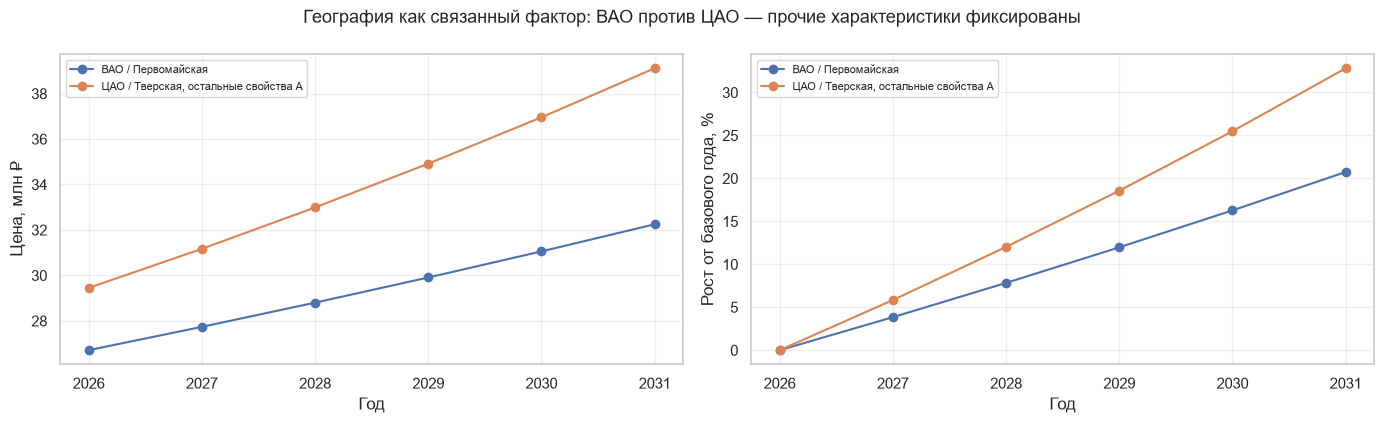

,Вариант,"Цена старта, млн ₽","Годовой рост, %","Рост за N лет, %"
0,ВАО / Первомайская,26.709,3.842,20.744
1,"ЦАО / Тверская, остальные свойства А",29.450,5.841,32.823


,Вариант,"Цена старта, млн ₽","Годовой рост, %","Рост за N лет, %"
0,ВАО / Первомайская,26.709070,3.842091,20.744434
1,"ЦАО / Тверская, остальные свойства А",29.449623,5.841148,32.822824


In [24]:
apt_geo={**base,'region':APARTMENT_B['region'], 'district':APARTMENT_B['district'], 'street':APARTMENT_B['street']}
compare_counterfactuals('География как связанный фактор: ВАО против ЦАО',
  [('ВАО / Первомайская',base),('ЦАО / Тверская, остальные свойства А',apt_geo)])


## 14. Итоговая сравнительная оценка точности

Рейтинг по MAE независимого теста 2026 года. Показатель «Точность, %» — `100 − MAPE`

,Место,Модель,"CV MAE, млн ₽","MAE, млн ₽","RMSE, млн ₽",R²,"MAPE, %","Точность, %",Выбрана по CV
0,1,CatBoost,6.350,5.883,9.296,0.544,20.827,79.173,да
1,2,HistGradientBoosting,6.374,5.897,9.286,0.545,20.861,79.139,нет
2,3,Статическая гедоническая Ridge,6.834,6.273,9.775,0.495,22.573,77.427,нет
3,4,Динамическая гедоническая Ridge,6.955,6.772,9.909,0.482,23.652,76.348,нет


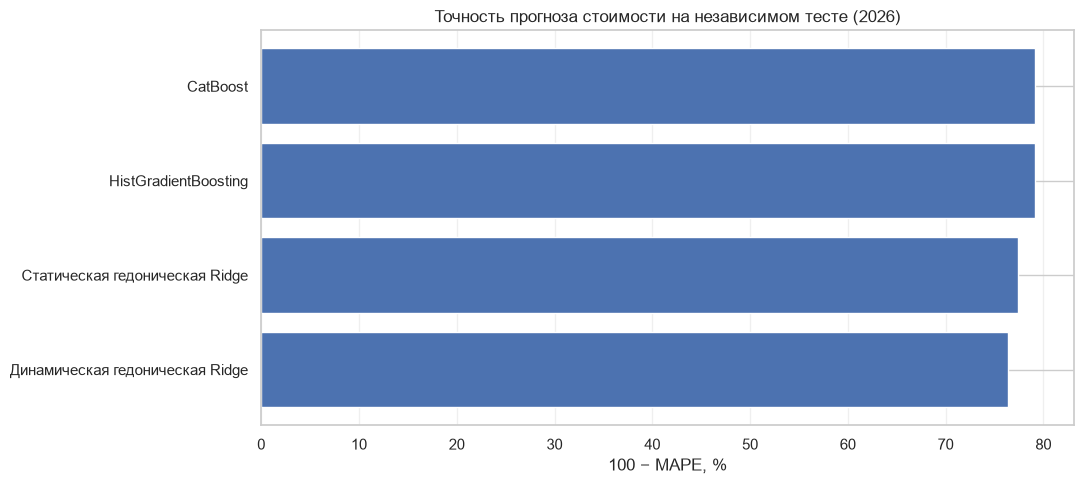

In [ ]:
show=['Место','Модель','CV MAE, млн ₽','MAE, млн ₽','RMSE, млн ₽','R²','MAPE, %','Точность, %','Выбрана по CV']
display(ranking[show].round(3))
fig,ax=plt.subplots(figsize=(11,5))
ax.barh(ranking['Модель'][::-1],ranking['Точность, %'][::-1])
ax.set(title='Точность прогноза стоимости на независимом тесте (2026)',xlabel='100 − MAPE, %')
ax.grid(axis='x',alpha=.3);plt.tight_layout();plt.show()

## 15. Экспериментальный прогноз стоимости двух квартир на 2026–2031 годы

Объекты: ВАО, Восточное Измайлово, ул. Первомайская (1980 г., 7-й этаж, 54 м²) и ЦАО, Тверской район, ул. Тверская (2005 г., 3-й этаж, 68 м²). Динамические траектории рассчитаны по гедонической Ridge с временными взаимодействиями признаков; результаты не подменяют сравнительную оценку моделей.


,Квартира,"Старт, млн ₽","Годовой рост, %","Рост за 5 лет, %","2031, млн ₽"
0,А — Первомайская,26.709,3.842,20.744,32.250
1,Б — Тверская,40.928,10.044,61.376,66.049


А — Первомайская:


,Год,"Прогноз цены, млн руб.","Годовой рост, %","Рост от базового года, %"
0,2026,26.709,NaN,0.000
1,2027,27.735,3.842,3.842
2,2028,28.801,3.842,7.832
3,2029,29.907,3.842,11.975
4,2030,31.056,3.842,16.277
5,2031,32.250,3.842,20.744


Б — Тверская:


,Год,"Прогноз цены, млн руб.","Годовой рост, %","Рост от базового года, %"
0,2026,40.928,NaN,0.000
1,2027,45.039,10.044,10.044
2,2028,49.563,10.044,21.097
3,2029,54.542,10.044,33.261
4,2030,60.020,10.044,46.646
5,2031,66.049,10.044,61.376


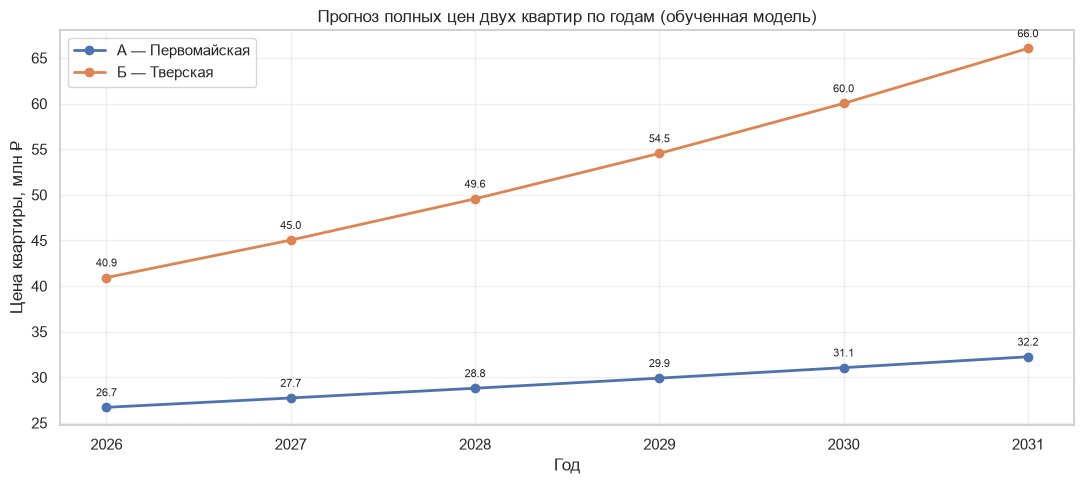

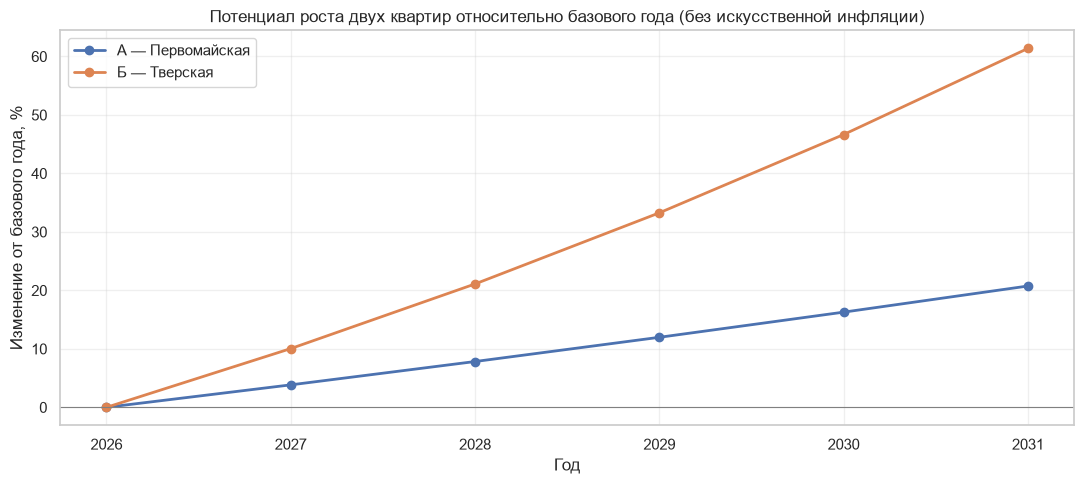

Модель сохранена в: moscow_apartment_forecast_research_v9_3sigma.joblib


In [ ]:
fc_a=forecast_apartment(APARTMENT_A,FORECAST_N)
fc_b=forecast_apartment(APARTMENT_B,FORECAST_N)
comparison_final=pd.DataFrame([
    {'Квартира':label,'Старт, млн ₽':float(fc.iloc[0]['Прогноз цены, млн руб.']),
     'Годовой рост, %':float(fc.iloc[1]['Годовой рост, %']),
     'Рост за 5 лет, %':float(fc.iloc[-1]['Рост от базового года, %']),
     '2031, млн ₽':float(fc.iloc[-1]['Прогноз цены, млн руб.'])}
     for label,fc in [('А — Первомайская',fc_a),('Б — Тверская',fc_b)]
])
display(comparison_final.round(3))
print('А — Первомайская:');display(fc_a.round(3))
print('Б — Тверская:');display(fc_b.round(3))
if np.isclose(fc_a.iloc[1]['Годовой рост, %'],fc_b.iloc[1]['Годовой рост, %'],atol=1e-5):
    warnings.warn('Индивидуальные темпы совпали. Пожалуйста проверьте насыщенность временных взаимодействий. Никаких искусственных поправок не применяется.')
fig,ax=plt.subplots(figsize=(11,5))
for label,data in [('А — Первомайская',fc_a),('Б — Тверская',fc_b)]:
    ax.plot(data['Год'],data['Прогноз цены, млн руб.'],marker='o',linewidth=2,label=label)
    for _,r in data.iterrows():ax.annotate(f"{r['Прогноз цены, млн руб.']:.1f}",
        (r['Год'],r['Прогноз цены, млн руб.']),xytext=(0,8),textcoords='offset points',fontsize=8,ha='center')
ax.set(title='Прогноз полных цен двух квартир по годам (обученная модель)',
       xlabel='Год',ylabel='Цена квартиры, млн ₽')
ax.grid(alpha=.3);ax.legend();plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(11,5))
for label,data in [('А — Первомайская',fc_a),('Б — Тверская',fc_b)]:
    ax.plot(data['Год'],data['Рост от базового года, %'],marker='o',linewidth=2,label=label)
ax.axhline(0,color='grey',linewidth=.8)
ax.set(title='Потенциал роста двух квартир относительно базового года',
       xlabel='Год',ylabel='Изменение от базового года, %')
ax.grid(alpha=.3);ax.legend();plt.tight_layout();plt.show()
print('Модель сохранена в:',BUNDLE_PATH)
